## Solve evolution equation of $\phi$ and background evolution simultaneously with energy injection

Here we solve the $\phi$ dynamics in the case of injection. We set a given mass, a given value od the injection $\xi$ on a given redshift bin. 


### Single value of $\xi$

In [1]:
import numpy as np
import local
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os
from matplotlib.pyplot import *

# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'
    
# Latex font
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
#plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D

In [2]:
import importlib
importlib.reload(local)

<module 'local' from '/Users/salvatoresamuelesirletti/Desktop/Work/Biref_iso_inject/local.py'>

In [3]:
a = np.logspace(-6, 0, 2000)
a_ini = a[0]
z = 1./a - 1.
#logms = [-30.5]
n, tf = 1, 100   #parameters of the  axion potential and axion energy

In [4]:
logm = -30.5
bphi0_ini = 1.
#bphi1_ini = -local.V_phi(1.,logm,tf,n,deriv=1)/(3*a_ini*(local.H0Mpc*local.Ea(a_ini))**2)
bphi1_ini = 0.
Phi = solve_ivp(local.EoM_phi, [a[0],1], [bphi0_ini,bphi1_ini], t_eval=a, args=[logm,tf,n]) #Without energy injection

In [5]:
#xi = 1.62811e-02 # This is the critical value using Planck params for mass -30.5. Above it the axion receive a kick-off.

xi  = 1.3e-02

eps = 1e-8
z_end = 50
z_start = 60
rtol = 1e-5
atol = 1e-7
theta_ini = 0.01
bphi0_ini = theta_ini * tf
bphi1_ini = 0.
#bphi1_ini = -local.V_phi(1.,logm,tf,n,deriv=1)/(3*a_ini*(local.H0Mpc*local.Ea(a_ini))**2)
phi = solve_ivp(local.EoM_phi, [a[0],1], [bphi0_ini,bphi1_ini], t_eval=a, args=[logm,tf,n,xi,eps,z_start,z_end, bphi0_ini], 
                atol=atol, rtol=rtol, method="RK45") #With energy injection



In [6]:
print("success =", phi.success)
print("status  =", phi.status)
print("message =", phi.message)
print("t shape =", phi.t.shape)
print("y shape =", phi.y.shape)

success = True
status  = 0
message = The solver successfully reached the end of the integration interval.
t shape = (2000,)
y shape = (2, 2000)


In [7]:
solphi0 = phi['y'][0] #field evoulution with energy injection

solphi1 = Phi['y'][0] #field evoulution without energy injection

#Renormalizing 

phi_inject = (solphi0 - solphi0[-1])/(1 - solphi0[-1])

phi_normal = (solphi1 - solphi1[-1])/(1 - solphi1[-1])

In [8]:
beta0 = 0.3
beta0_deg = beta0 # Value of beta measured today
beta0_rad = 0.3 * np.pi / 180      # coupling g*phi_ini/2, in rad. Need also to pass to CLASS in create_inifile

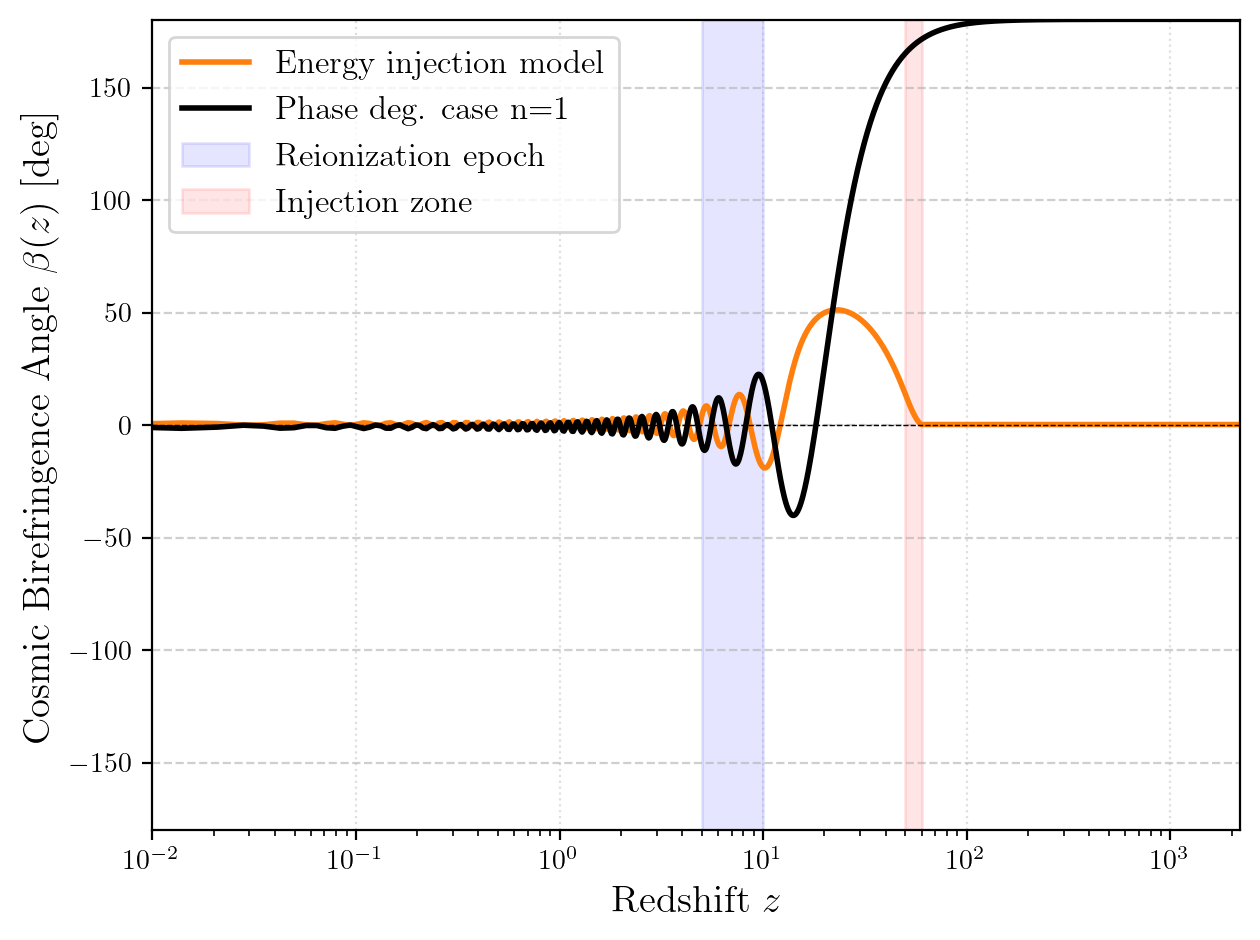

In [9]:
#Plot of beta from injection model and large CB angle


plt.figure()
plt.xscale('log')
plt.xlim(0.01, 2.2e3)
plt.xlabel(r'Redshift $z$', fontsize=14)
plt.ylim(-180, 180)
plt.ylabel(r'Cosmic Birefringence Angle $\beta(z)$ [deg]', fontsize=14)
plt.plot(z[::-1], phi_inject[::-1] * beta0, label='Energy injection model', color='C1', lw=2) #Injection model
plt.plot(z[::-1], phi_normal[::-1] * (180*1 + beta0), label='Phase deg. case n=1', color='k', linestyle='-', lw=2) #large CB angle
plt.axvspan(5, 10, alpha=0.1, color='blue', label='Reionization epoch')
plt.axvspan(z_end, z_start, alpha=0.1, color='red', label='Injection zone')
#plt.axhline(beta0, color='k', ls='--', label=r'Target $\beta_0 = 0.3^\circ$')
plt.axhline(0, color='k', ls='--', lw=0.5)
plt.legend(fontsize=12, loc='best')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.grid(axis='x', linestyle=':', alpha=0.4)
plt.tight_layout()

plt.show()

### Different values of $\xi$

In [10]:
# Define a list of xi values:

asize = 15  #array size

np.random.seed(42) #random seed

max_xi = 1.92811e-02
min_xi = 0

xi_array_random = np.random.uniform(low=min_xi, high =max_xi, size=asize)
xi_array_random = np.sort(xi_array_random)

xi_values = xi_array_random.tolist()

print(xi_values)

[0.00039689169296679654, 0.0011199159345762705, 0.003007745946054357, 0.0030082110082346627, 0.0035057853752168276, 0.00409413162689891, 0.007221545485507881, 0.011542794099651482, 0.011590158652921982, 0.013652418179743333, 0.014113648391459881, 0.016050409801537012, 0.016700828884301102, 0.018330817613320234, 0.018700928850520628]


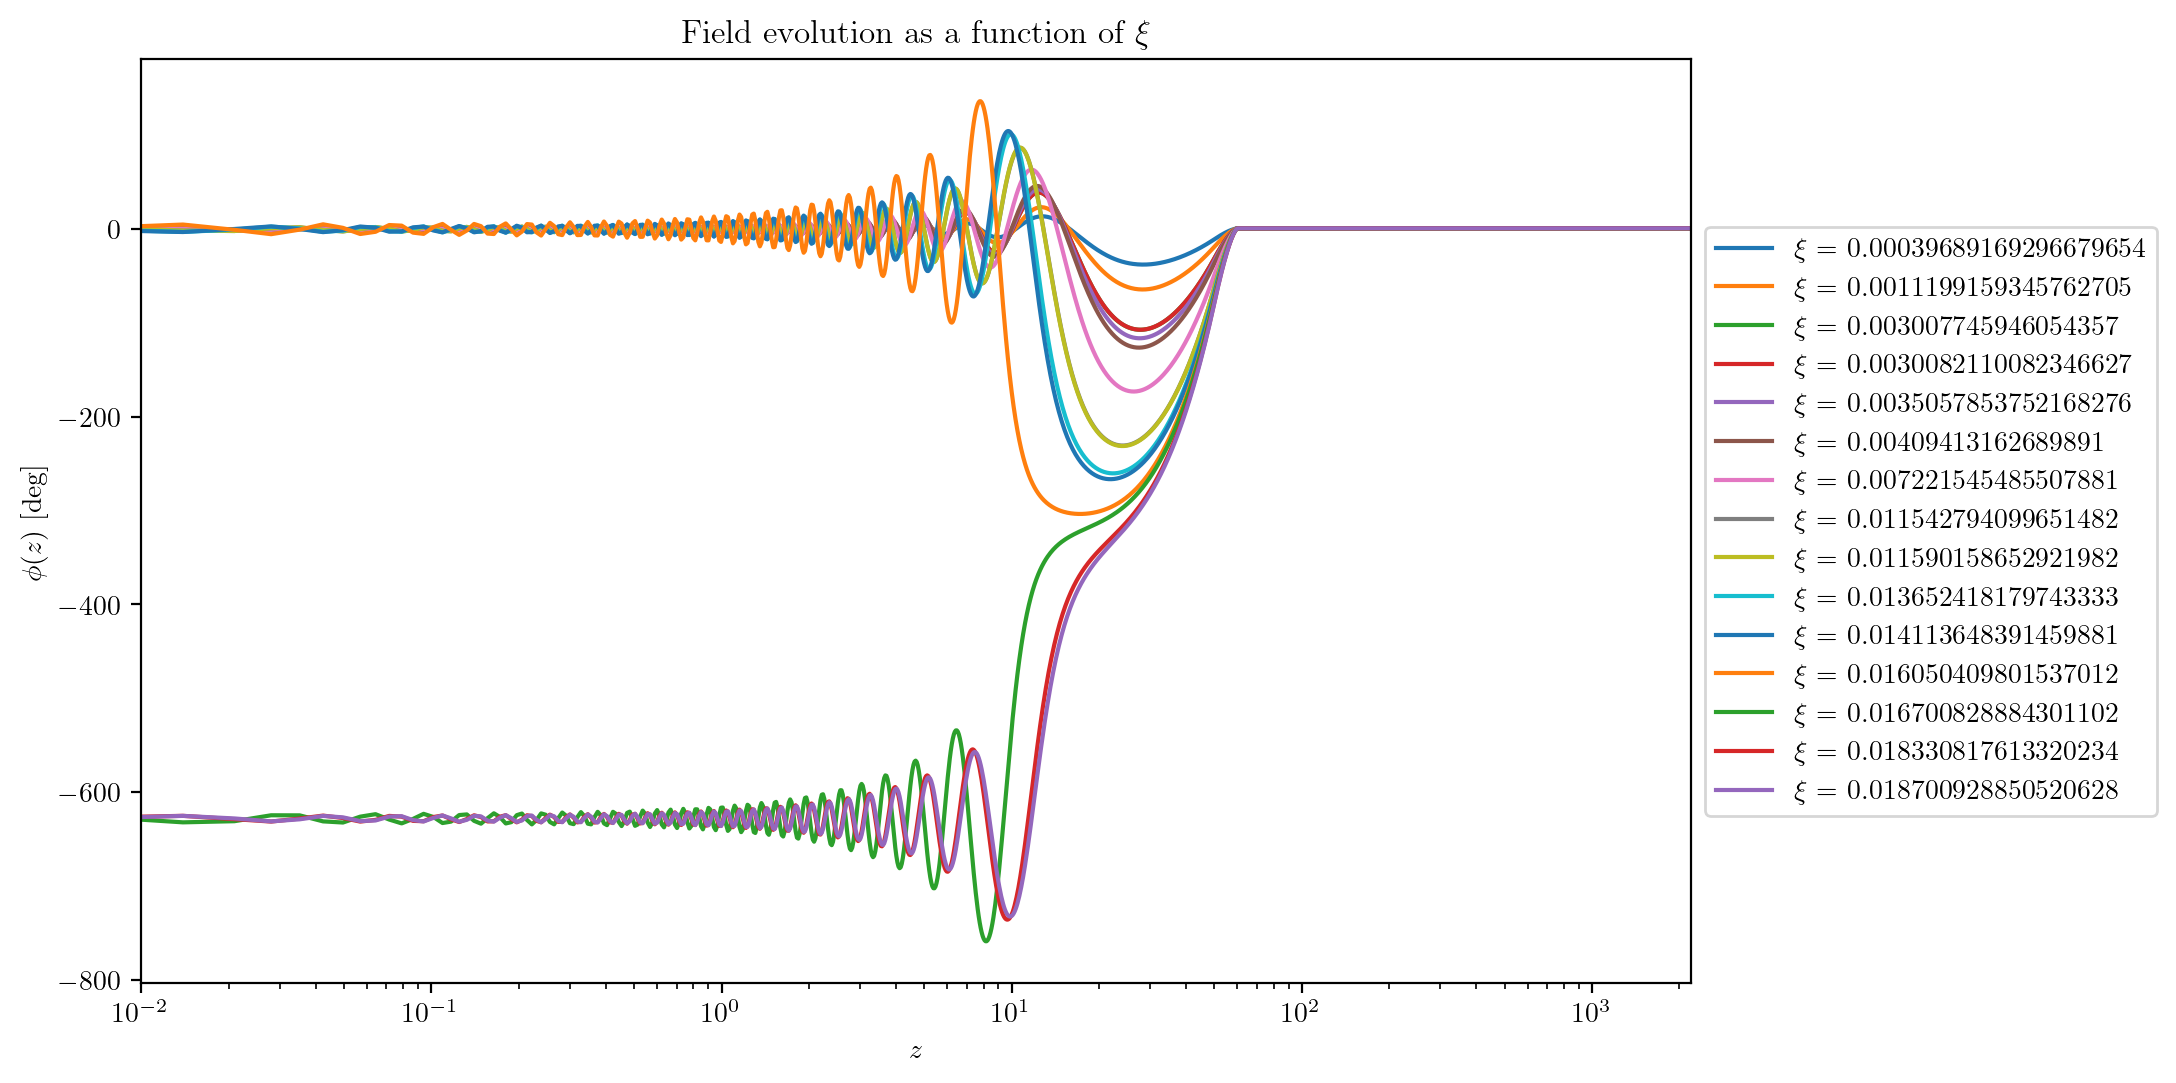

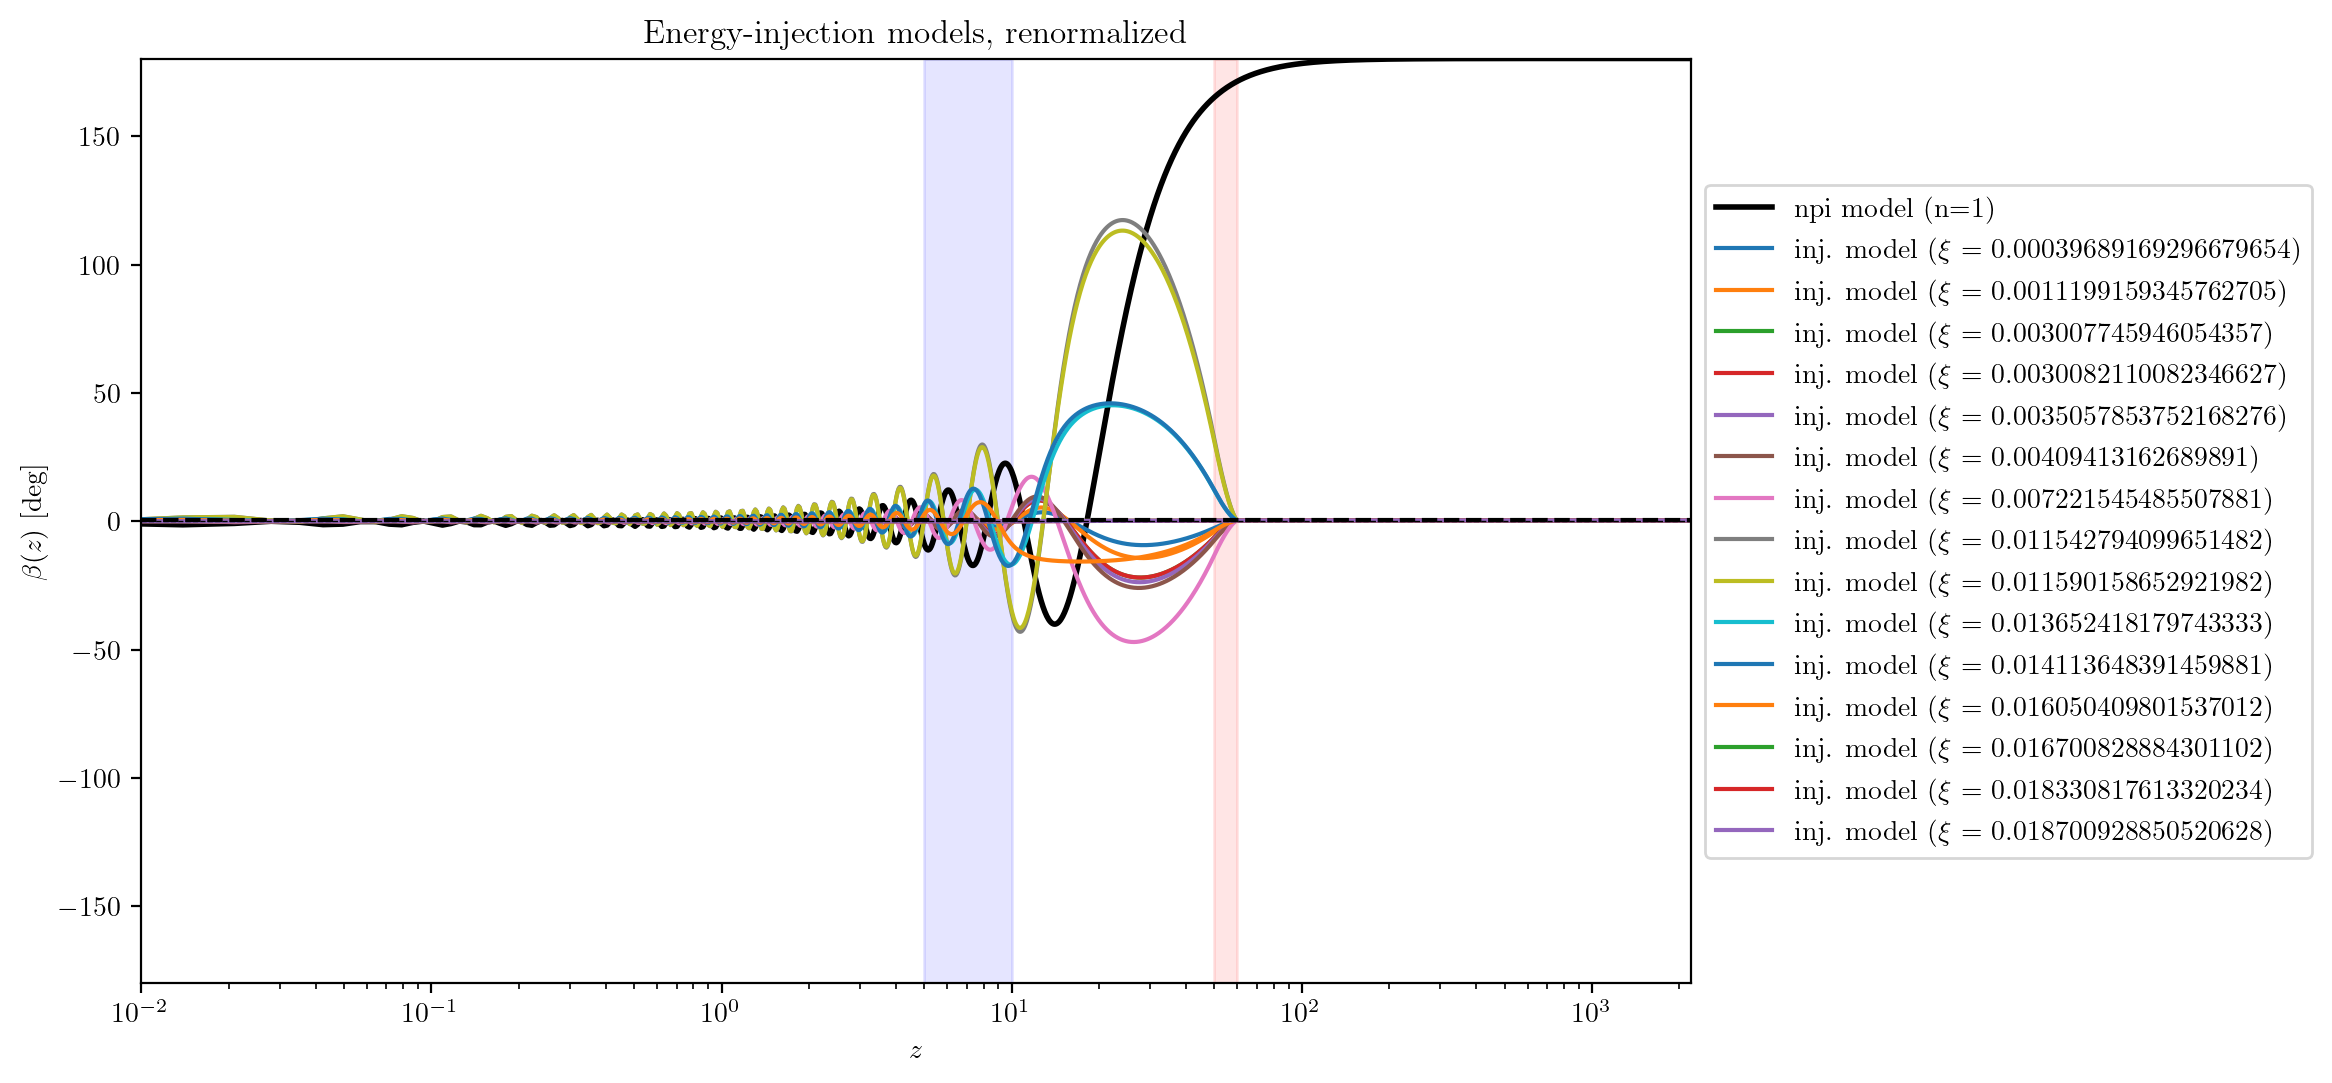

In [11]:
# --- FIRST PLOT: Field evolution ---
figure(figsize=(10, 6))
xscale('log')
xlim(0.01, 2.2e3)
xlabel(r'$z$')
ylabel(r'$\phi(z)$ [deg]')
title(r'Field evolution as a function of $\xi$')

results_phi = []

for xi_val in xi_values:
    phi_temp = solve_ivp(local.EoM_phi, [a[0], 1], [bphi0_ini, bphi1_ini],
                         t_eval=a, args=[logm, tf, n, xi_val, eps, z_start, z_end, bphi0_ini],
                         atol=atol, rtol=rtol, method="RK45")

    results_phi.append(phi_temp)
    solphi0_temp = phi_temp.y[0]

    plot(z[::-1], solphi0_temp[::-1], label=f'$\\xi$ = {xi_val}')

legend(loc='center left', bbox_to_anchor=(1, 0.5))
show()


# --- SECOND PLOT: Renormalized models ---
figure(figsize=(10, 6))
xscale('log')
xlim(0.01, 2.2e3)
ylim(-180, 180)
xlabel(r'$z$')
ylabel(r'$\beta(z)$ [deg]')
title('Energy-injection models, renormalized')

plot(z[::-1], phi_normal[::-1]*(180*1+beta0), label='npi model (n=1)', color='black', lw=2)

for i, xi_val in enumerate(xi_values):
    phi_temp = results_phi[i]
    solphi0_temp = phi_temp.y[0]

    phi_inject_temp = (solphi0_temp - solphi0_temp[-1]) / (1 - solphi0_temp[-1])

    plot(z[::-1], phi_inject_temp[::-1]*beta0, label=f'inj. model ($\\xi$ = {xi_val})')

axvspan(5, 10, alpha=0.1, color='blue')
axvspan(z_end, z_start, alpha=0.1, color='red')  # Injection zone
axhline(beta0, color='k', ls='--')
axhline(0, color='k', ls='--', lw=0.5)

legend(loc='center left', bbox_to_anchor=(1, 0.5))
show()

## Computing the CMB power spectra in the case of injection and CB

To compute the $C_\ell$ we use pyrefCLASS (wrapper for birefCLASS). 

We compute the $C_\ell$ for all the values of $\xi$ in the array defined above. 

In [12]:
dir_pyrefclass = '//Users/salvatoresamuelesirletti/pyrefCLASS' # directory of pyrefCLASS
sys.path.append(dir_pyrefclass)
import pyrefCLASS as rot

import importlib
importlib.reload(rot)

import numpy as np, local, os, tqdm, sys
from scipy.integrate import solve_ivp
from matplotlib.pyplot import *

In [13]:
# Initial setup of birefCLASS


Neta  = 10000                       # number of time steps for output phi(eta)
mass  = np.array([logm])            # log10 m_phi

ow = True

t=0.09   #tau used to compute the spectra.
Asplanck = 2.1e-9
tau_planck = 0.054
const_planck = 2.1e-9*np.exp(-2*tau_planck)  #consistency relation

outroot = '/Users/salvatoresamuelesirletti/Desktop/Work/Biref_iso_inject/output/'


os.makedirs(outroot, exist_ok=True)



In [14]:
#Computing the spectra in presence of injection xi, using birefCLASS


print("Beginning to compute...")

for x in tqdm.tqdm(xi_values, desc="Computing the spectra for each xi value"):
    base_tag = 'inject_tau' + str(t) + '_logm' + str(logm) + '_xi' + str(x) + '_N' + str(Neta)
    ofile = outroot + base_tag + '_cl.dat'
    
    if os.path.exists(ofile) and not ow:
        print(ofile + ' exist, skipping computation.', end='\n', flush=True)
        continue
    else:
        ln10As = np.log(1e10 * const_planck * np.exp(2 * t))
        dynamics_file = rot.dir_phi + base_tag
        
        if ow and os.path.exists(dynamics_file):
            os.remove(dynamics_file)
        
        rot.export_axion_dynamics_a(Neta, local.EoM_phi, [logm, tf, n, x, eps, z_start, z_end,bphi0_ini], rot.dir_phi + base_tag)
        rot.create_inifile(
            beta0_rad, base_tag, Neta, base_tag, default_ini_file='biref_default_inject.ini', tau_reio=t, ln10As=ln10As,
            outroot=outroot, phi_dynamics_dir=rot.dir_phi
        )
        os.system(
            rot.path_to_birefCLASS + '/class ' + rot.dir_ini + base_tag + '.ini ' + rot.path_to_birefCLASS + '/cl_ref_biref.pre > test.txt'
        )
        for tag in ['cls.dat', 'clt.dat', 'parameters.ini', 'primordial_Pk.dat', 'thermodynamics.dat', 'unused_parameters', 'background.dat']:
            os.system('rm -rf ' + outroot + base_tag + '_' + tag)
        os.system('rm -rf ' + rot.dir_ini + base_tag + '.ini')

print("Finished.")

Beginning to compute...


Computing the spectra for each xi value:   0%|          | 0/15 [00:00<?, ?it/s]

Computing the spectra for each xi value: 100%|██████████| 15/15 [00:53<00:00,  3.59s/it]

Finished.


In [15]:
#Load the computed spectra

column_spectrum = 2  #Choose which spectrum you want to see in the plots (ell, TT, EE, BB, TE, TB, EB)

spectra = []
for x in xi_values:
    base_tag = 'inject_tau' + str(t) + '_logm' + str(logm) + '_xi' + str(x) + '_N' + str(Neta)
    file_path = outroot + base_tag + '_cl.dat'
    if os.path.exists(file_path):
        lcl = np.loadtxt(file_path, unpack=True, max_rows=3000)
        spectra.append(lcl)
    else:
        spectra.append(None)
        print(f"File non trovato per xi = {x}")

/var/folders/jc/kky54qz15j50ck9_kzrzk_d80000gn/T/ipykernel_22098/2444084735.py:10: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=3000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  lcl = np.loadtxt(file_path, unpack=True, max_rows=3000)


Now we plot an anymation to see how the field dynamics, the CB angle, and $C_\ell^{EE}$ change by chaning $\xi$. 

In [16]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import os

FONTSIZE_LABEL = 17
FONTSIZE_TICK = 14
FONTSIZE_XI = 14
FONTSIZE_TITLE = 20

pi_tf = np.pi * tf  # kick-out limit in units of phi_ini

N = len(xi_values)
colors = plt.cm.plasma(np.linspace(0.1, 0.9, N))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle(rf"$\log(m) = {logm}$, $\tau = {t}$", fontsize=FONTSIZE_TITLE)

# --- Subplot 1: raw field ---
ax1.set_xscale("log")
ax1.set_xlim(0.01, 2.2e3)
ax1.set_ylim(-1000, 1000)
ax1.set_xlabel(r"Redshift $z$", fontsize=FONTSIZE_LABEL)
ax1.set_ylabel(r"$\varphi(z)$ [deg]", fontsize=FONTSIZE_LABEL)
ax1.tick_params(labelsize=FONTSIZE_TICK)
ax1.axvspan(5, 10, alpha=0.1, color="blue", label="Reionization epoch")
ax1.axvspan(z_end, z_start, alpha=0.1, color="red", label="Injection zone")
ax1.axhline(pi_tf, color="gray", ls=":", lw=1.5, label="Kick-out limit")
ax1.axhline(-pi_tf, color="gray", ls=":", lw=1.5)
ax1.legend(fontsize=FONTSIZE_TICK, loc="upper right")
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.grid(axis='x', linestyle=':', alpha=0.3)

# --- Subplot 2: renormalized beta ---
ax2.set_xscale("log")
ax2.set_xlim(0.01, 2.2e3)
ax2.set_ylim(-180, 180)
ax2.set_xlabel(r"Redshift $z$", fontsize=FONTSIZE_LABEL)
ax2.set_ylabel(r"$\beta(z)$ [deg]", fontsize=FONTSIZE_LABEL)
ax2.tick_params(labelsize=FONTSIZE_TICK)
ax2.axvspan(5, 10, alpha=0.1, color="blue")
ax2.axvspan(z_end, z_start, alpha=0.1, color="red")
ax2.axhline(beta0, color="k", ls="--", lw=1, label=rf"$\beta_0 = {beta0}^\circ$")
ax2.axhline(0, color="k", ls="--", lw=0.5)
ax2.plot(z[::-1], phi_normal[::-1] * (180 * 1 + beta0),
         color="black", lw=2, label="npi model (n=1)", zorder=10)
ax2.legend(fontsize=FONTSIZE_TICK, loc="upper right")
ax2.grid(axis='y', linestyle='--', alpha=0.4)
ax2.grid(axis='x', linestyle=':', alpha=0.3)

# --- Subplot 3: spectra ---
ax3.set_xlim(1, 50)
ax3.set_ylim(-3e-15, 2e-14)
ax3.set_xlabel(r"Multipole $\ell$", fontsize=FONTSIZE_LABEL)
ax3.set_ylabel(r"$\ell(\ell+1)C_\ell^{EE}/2\pi$", fontsize=FONTSIZE_LABEL)
ax3.tick_params(labelsize=FONTSIZE_TICK)
ax3.axhline(0, color="k", ls="--", lw=0.5)
ax3.grid(axis='y', linestyle='--', alpha=0.4)
ax3.grid(axis='x', linestyle=':', alpha=0.3)

hist_lines1 = [ax1.plot([], [], color=colors[i], lw=1, alpha=0.25)[0] for i in range(N)]
hist_lines2 = [ax2.plot([], [], color=colors[i], lw=1, alpha=0.25)[0] for i in range(N)]
hist_lines3 = [ax3.plot([], [], color=colors[i], lw=1, alpha=0.25)[0] for i in range(N)]

active_line1, = ax1.plot([], [], color="red", lw=2.5, zorder=10)
active_line2, = ax2.plot([], [], color="red", lw=2.5, zorder=10)
active_line3, = ax3.plot([], [], color="red", lw=2.5, zorder=10)

xi_text1 = ax1.text(0.03, 0.95, "", transform=ax1.transAxes,
                     fontsize=FONTSIZE_XI, color="red", va="top", fontweight="bold")
xi_text2 = ax2.text(0.03, 0.95, "", transform=ax2.transAxes,
                     fontsize=FONTSIZE_XI, color="red", va="top", fontweight="bold")
xi_text3 = ax3.text(0.03, 0.95, "", transform=ax3.transAxes,
                     fontsize=FONTSIZE_XI, color="red", va="top", fontweight="bold")

fig.tight_layout()


def init():
    for l1, l2, l3 in zip(hist_lines1, hist_lines2, hist_lines3):
        l1.set_data([], [])
        l2.set_data([], [])
        l3.set_data([], [])
    active_line1.set_data([], [])
    active_line2.set_data([], [])
    active_line3.set_data([], [])
    xi_text1.set_text("")
    xi_text2.set_text("")
    xi_text3.set_text("")
    return (hist_lines1 + hist_lines2 + hist_lines3 +
            [active_line1, active_line2, active_line3,
             xi_text1, xi_text2, xi_text3])


def update(frame):
    xi_val = xi_values[frame]
    y = results_phi[frame].y[0]

    # Subplot 1 — raw field
    for i in range(N):
        if i < frame:
            hist_lines1[i].set_data(z[::-1], results_phi[i].y[0][::-1])
        else:
            hist_lines1[i].set_data([], [])
    active_line1.set_data(z[::-1], y[::-1])

    # Subplot 2 — renormalized
    phi_inj = (y - y[-1]) / (1 - y[-1])
    for i in range(N):
        if i < frame:
            y_i = results_phi[i].y[0]
            phi_inj_i = (y_i - y_i[-1]) / (1 - y_i[-1])
            hist_lines2[i].set_data(z[::-1], phi_inj_i[::-1] * beta0)
        else:
            hist_lines2[i].set_data([], [])
    active_line2.set_data(z[::-1], phi_inj[::-1] * beta0)

    # Subplot 3 — spectra
    for i in range(N):
        if i < frame and spectra[i] is not None:
            hist_lines3[i].set_data(spectra[i][0], spectra[i][column_spectrum])
        else:
            hist_lines3[i].set_data([], [])
    if spectra[frame] is not None:
        active_line3.set_data(spectra[frame][0], spectra[frame][column_spectrum])
    else:
        active_line3.set_data([], [])

    label = rf"$\xi = {xi_val:.4g}$"
    xi_text1.set_text(label)
    xi_text2.set_text(label)
    xi_text3.set_text(label)

    return (hist_lines1 + hist_lines2 + hist_lines3 +
            [active_line1, active_line2, active_line3,
             xi_text1, xi_text2, xi_text3])


ani = animation.FuncAnimation(
    fig, update,
    frames=N,
    init_func=init,
    interval=900,
    blit=True,
    repeat=True
)

plt.close(fig)
HTML(ani.to_jshtml())

In [17]:
#ani.save("phi_evolution_logma30.gif", writer="pillow", fps=1, dpi=120)  # Save as GIFT

ani.save("phi_evolution_logma30.mp4", writer="ffmpeg", fps=1, dpi=150)   #Save as MP4